# Financial Transaction Intelligence & Fraud Detection Using Machine Learning

## Project Overview

This project explores synthetic mobile money transaction data to identify patterns associated with fraudulent transactions using data analysis and machine learning.

The project covers data cleaning, exploratory data analysis, feature engineering, chronological data splitting, model development, and performance evaluation.

## Objectives

- Explore transaction patterns and fraud distribution.
- Analyse transaction amounts and account balance changes.
- Engineer historical transaction features.
- Develop a Random Forest classification model.
- Evaluate model performance using appropriate classification metrics.

## 1. Dataset Loading and Initial Inspection

In [1]:
import pandas as pd
import os

file_path = r"C:\Users\dell\Downloads\synthetic_mobile_money_transaction_dataset (1).csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (1720181, 10)


In [2]:
# Display all column names
print("COLUMN NAMES:")
print(df.columns.tolist())

# Display first five records
print("\nFIRST 5 RECORDS:")
display(df.head())

# Check data types and non-null counts
print("\nDATASET INFORMATION:")
df.info()

COLUMN NAMES:
['step', 'transactionType', 'amount', 'initiator', 'oldBalInitiator', 'newBalInitiator', 'recipient', 'oldBalRecipient', 'newBalRecipient', 'isFraud']

FIRST 5 RECORDS:


,step,transactionType,amount,initiator,oldBalInitiator,newBalInitiator,recipient,oldBalRecipient,newBalRecipient,isFraud
0,0,TRANSFER,19824.96,4537027967639631,187712.18,167887.22,4875702729424478,8.31,19833.27,1
1,0,PAYMENT,598.97,4296267625767470,8.92,8.92,25-0000401,0.00,0.00,0
2,0,PAYMENT,545.85,4178224023847746,93.60,-452.25,13-0001587,0.00,545.85,0
3,0,TRANSFER,19847.01,4178224023847746,-452.25,-20299.26,4096920916696293,4011.72,23858.74,1
4,0,PAYMENT,546.89,4779013371563747,159148.76,158601.88,75-0003564,0.00,546.89,0



DATASET INFORMATION:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1720181 entries, 0 to 1720180
Data columns (total 10 columns):
 #   Column           Dtype  
---  ------           -----  
 0   step             int64  
 1   transactionType  object 
 2   amount           float64
 3   initiator        int64  
 4   oldBalInitiator  float64
 5   newBalInitiator  float64
 6   recipient        object 
 7   oldBalRecipient  float64
 8   newBalRecipient  float64
 9   isFraud          int64  
dtypes: float64(5), int64(3), object(2)
memory usage: 131.2+ MB


## 2. Data Quality Assessment and Exploratory Data Analysis

In [3]:

# 1. Missing values
print("MISSING VALUES")
print(df.isnull().sum())

# 2. Duplicate records
print("\nDUPLICATE ROWS")
print(df.duplicated().sum())

# 3. Transaction type distribution
print("\nTRANSACTION TYPE DISTRIBUTION")
print(df['transactionType'].value_counts())

# 4. Fraud distribution
print("\nFRAUD DISTRIBUTION")
print(df['isFraud'].value_counts())

print("\nFRAUD PERCENTAGE")
print(df['isFraud'].value_counts(normalize=True) * 100)

# 5. Numerical summary
print("\nNUMERICAL SUMMARY")
display(df[['step', 'amount',
            'oldBalInitiator', 'newBalInitiator',
            'oldBalRecipient', 'newBalRecipient']].describe())


MISSING VALUES
step               0
transactionType    0
amount             0
initiator          0
oldBalInitiator    0
newBalInitiator    0
recipient          0
oldBalRecipient    0
newBalRecipient    0
isFraud            0
dtype: int64

DUPLICATE ROWS
0

TRANSACTION TYPE DISTRIBUTION
transactionType
PAYMENT       667245
TRANSFER      569328
DEPOSIT       384431
WITHDRAWAL     93785
DEBIT           5392
Name: count, dtype: int64

FRAUD DISTRIBUTION
isFraud
0    1544663
1     175518
Name: count, dtype: int64

FRAUD PERCENTAGE
isFraud
0    89.796539
1    10.203461
Name: proportion, dtype: float64

NUMERICAL SUMMARY


,step,amount,oldBalInitiator,newBalInitiator,oldBalRecipient,newBalRecipient
count,1.720181e+06,1.720181e+06,1.720181e+06,1.720181e+06,1.720181e+06,1.720181e+06
mean,6.555529e+01,5.253868e+04,2.433758e+06,2.443880e+06,1.085083e+05,1.222772e+05
std,4.467368e+01,8.835650e+04,1.307615e+06,1.297181e+06,2.830138e+05,3.192277e+05
min,0.000000e+00,2.400000e-01,-1.999971e+05,-1.999971e+05,-1.983685e+05,-1.357280e+05
25%,2.300000e+01,6.064600e+02,1.577186e+06,1.600496e+06,1.606423e+04,2.496233e+04
50%,5.400000e+01,1.729825e+04,2.619827e+06,2.625680e+06,6.313018e+04,7.448161e+04
75%,1.060000e+02,7.116149e+04,3.361338e+06,3.361872e+06,1.373822e+05,1.431702e+05
max,1.430000e+02,2.142928e+06,1.224469e+07,1.224469e+07,1.188554e+07,1.206621e+07


### Key Findings

- The dataset contains 1,720,181 transactions and 10 columns.
- No missing values or duplicate records were found.
- All fraud-labelled transactions belong to the TRANSFER category.
- Approximately 10.20% of all transactions are labelled as fraudulent.

These findings provide an overview of the dataset and guide the subsequent fraud analysis.

## 3. Fraud Distribution by Transaction Type

In [4]:

import pandas as pd
import numpy as np

fraud_by_type = (
    df.groupby('transactionType')
      .agg(
          total_transactions=('isFraud', 'count'),
          fraudulent_transactions=('isFraud', 'sum'),
          average_amount=('amount', 'mean')
      )
)

fraud_by_type['fraud_rate_pct'] = (
    fraud_by_type['fraudulent_transactions'] /
    fraud_by_type['total_transactions'] * 100
)

fraud_by_type = fraud_by_type.sort_values(
    'fraud_rate_pct', ascending=False
)

display(fraud_by_type.round(2))


,total_transactions,fraudulent_transactions,average_amount,fraud_rate_pct
transactionType,,,,
TRANSFER,569328,175518,41798.18,30.83
DEBIT,5392,0,6919.28,0.00
DEPOSIT,384431,0,138554.55,0.00
PAYMENT,667245,0,1620.28,0.00
WITHDRAWAL,93785,0,130042.84,0.00


### Key Findings

- TRANSFER is the only transaction type containing fraud-labelled records.
- Out of 569,328 transfer transactions, 175,518 are labelled as fraudulent.
- The fraud-label rate among transfers is approximately 30.83%.
- PAYMENT, DEPOSIT, WITHDRAWAL and DEBIT contain no fraud-labelled records.

**Interpretation:** In this synthetic dataset, fraud labels are concentrated entirely in transfer transactions. This dataset-specific pattern should not be assumed to represent real-world financial fraud.

## 4. Transaction Amount Analysis

In [5]:

amount_comparison = (
    df.groupby('isFraud')['amount']
      .agg(['count', 'mean', 'median', 'min', 'max'])
)

amount_comparison.index = ['Non-Fraud', 'Fraud']

display(amount_comparison.round(2))


,count,mean,median,min,max
Non-Fraud,1544663,55612.54,17062.90,0.24,2142928.28
Fraud,175518,25486.86,19631.62,16804.02,632938.42



### Key Findings

1. Non-fraud transactions have a higher average transaction amount than fraud-labelled transactions.
2. The median transaction amount is slightly higher for fraud-labelled transactions.
3. Non-fraud transactions show a substantially higher maximum transaction amount.
4. These differences suggest that transaction amount alone may not reliably distinguish fraudulent transactions.


## 5. Balance-Based Feature Engineering

In [6]:

df['sender_balance_change'] = (
    df['oldBalInitiator'] - df['newBalInitiator']
)

df['recipient_balance_change'] = (
    df['newBalRecipient'] - df['oldBalRecipient']
)

df['sender_balance_difference'] = (
    df['sender_balance_change'] - df['amount']
)

df['recipient_balance_difference'] = (
    df['recipient_balance_change'] - df['amount']
)

display(
    df.groupby('isFraud')[
        ['sender_balance_difference',
         'recipient_balance_difference']
    ].agg(['mean', 'median', 'std']).round(2)
)


sender_balance_difference                    \
                             mean median        std   
isFraud                                               
0                       -69495.23   -0.0  143327.93   
1                        -2513.88   -0.0   13799.10   

        recipient_balance_difference                   
                                mean median       std  
isFraud                                                
0                          -42889.50   -0.0  76573.12  
1                           -2513.88    0.0  13799.10

In [7]:

# Filter transfer transactions
transfer_df = df[df['transactionType'] == 'TRANSFER'].copy()

# Compare balance differences by fraud label
transfer_balance_analysis = (
    transfer_df.groupby('isFraud')
    .agg(
        transaction_count=('amount', 'count'),
        avg_amount=('amount', 'mean'),
        sender_difference_mean=('sender_balance_difference', 'mean'),
        sender_difference_std=('sender_balance_difference', 'std'),
        recipient_difference_mean=('recipient_balance_difference', 'mean'),
        recipient_difference_std=('recipient_balance_difference', 'std')
    )
)

display(transfer_balance_analysis.round(2))


,transaction_count,avg_amount,sender_difference_mean,sender_difference_std,recipient_difference_mean,recipient_difference_std
isFraud,,,,,,
0,393810,49068.01,-1859.59,20168.12,-1859.59,20168.12
1,175518,25486.86,-2513.88,13799.10,-2513.88,13799.10


In [8]:

# Calculate balance discrepancies for transfers
transfer_df['sender_abs_difference'] = (
    transfer_df['sender_balance_difference'].abs()
)

transfer_df['recipient_abs_difference'] = (
    transfer_df['recipient_balance_difference'].abs()
)

# Percentage of transfers with balance discrepancies
consistency = (
    transfer_df.groupby('isFraud')
    .agg(
        sender_mismatch_pct=(
            'sender_abs_difference',
            lambda x: (x > 0.01).mean() * 100
        ),
        recipient_mismatch_pct=(
            'recipient_abs_difference',
            lambda x: (x > 0.01).mean() * 100
        )
    )
)

display(consistency.round(2))


,sender_mismatch_pct,recipient_mismatch_pct
isFraud,,
0,14.21,10.78
1,17.12,13.66


# Create transaction-level behavioural features

In [9]:

# Create transaction-level behavioural features

transfer_df = df[df['transactionType'] == 'TRANSFER'].copy()

transfer_df['sender_balance_change'] = (
    transfer_df['oldBalInitiator'] - transfer_df['newBalInitiator']
)

transfer_df['recipient_balance_change'] = (
    transfer_df['newBalRecipient'] - transfer_df['oldBalRecipient']
)

transfer_df['sender_balance_mismatch'] = (
    transfer_df['sender_balance_change'] - transfer_df['amount']
).abs()

transfer_df['recipient_balance_mismatch'] = (
    transfer_df['recipient_balance_change'] - transfer_df['amount']
).abs()

transfer_df['sender_mismatch_flag'] = (
    transfer_df['sender_balance_mismatch'] > 0.01
).astype(int)

transfer_df['recipient_mismatch_flag'] = (
    transfer_df['recipient_balance_mismatch'] > 0.01
).astype(int)

transfer_df['amount_to_sender_balance_ratio'] = (
    transfer_df['amount'] /
    (transfer_df['oldBalInitiator'].abs() + 1)
)

transfer_df['amount_to_recipient_balance_ratio'] = (
    transfer_df['amount'] /
    (transfer_df['oldBalRecipient'].abs() + 1)
)

display(transfer_df.head())


,step,transactionType,amount,initiator,oldBalInitiator,newBalInitiator,recipient,oldBalRecipient,newBalRecipient,isFraud,sender_balance_change,recipient_balance_change,sender_balance_difference,recipient_balance_difference,sender_balance_mismatch,recipient_balance_mismatch,sender_mismatch_flag,recipient_mismatch_flag,amount_to_sender_balance_ratio,amount_to_recipient_balance_ratio
0,0,TRANSFER,19824.96,4537027967639631,187712.18,167887.22,4875702729424478,8.31,19833.27,1,19824.96,19824.96,-7.275958e-12,0.00,7.275958e-12,0.00,0,0,0.105613,2129.426423
3,0,TRANSFER,19847.01,4178224023847746,-452.25,-20299.26,4096920916696293,4011.72,23858.74,1,19847.01,19847.02,0.000000e+00,0.01,0.000000e+00,0.01,0,1,43.788218,4.946024
5,0,TRANSFER,16973.75,4779013371563747,158601.88,141628.12,4593247015015219,54.33,17028.08,1,16973.76,16973.75,1.000000e-02,0.00,1.000000e-02,0.00,1,0,0.107020,306.772998
7,0,TRANSFER,21103.99,4479448076398077,261291.46,240187.47,4649550475321678,19.63,21123.63,1,21103.99,21104.00,-1.091394e-11,0.01,1.091394e-11,0.01,0,0,0.080768,1022.975763
9,0,TRANSFER,16908.07,4587942659105635,4160.05,4160.05,4863167876028593,66.12,66.12,1,0.00,0.00,-1.690807e+04,-16908.07,1.690807e+04,16908.07,1,1,4.063414,251.908075


In [10]:

# Compare engineered features for fraud and non-fraud transfers

feature_comparison = (
    transfer_df.groupby('isFraud')
    .agg(
        transaction_count=('amount', 'count'),
        median_amount=('amount', 'median'),
        median_sender_ratio=('amount_to_sender_balance_ratio', 'median'),
        median_recipient_ratio=('amount_to_recipient_balance_ratio', 'median'),
        sender_mismatch_rate=('sender_mismatch_flag', 'mean'),
        recipient_mismatch_rate=('recipient_mismatch_flag', 'mean')
    )
)

feature_comparison['sender_mismatch_rate'] *= 100
feature_comparison['recipient_mismatch_rate'] *= 100

display(feature_comparison.round(3))


,transaction_count,median_amount,median_sender_ratio,median_recipient_ratio,sender_mismatch_rate,recipient_mismatch_rate
isFraud,,,,,,
0,393810,19733.60,0.009,0.997,14.208,10.784
1,175518,19631.62,0.009,1.012,17.117,13.658


## 7. Statistical Analysis of Fraud Indicators

In [11]:

print("Fraud label counts:")
print(transfer_df['isFraud'].value_counts())

print("\nSender mismatch rates:")
print(
    transfer_df.groupby('isFraud')['sender_mismatch_flag']
    .mean().mul(100)
)

print("\nRecipient mismatch rates:")
print(
    transfer_df.groupby('isFraud')['recipient_mismatch_flag']
    .mean().mul(100)
)


Fraud label counts:
isFraud
0    393810
1    175518
Name: count, dtype: int64

Sender mismatch rates:
isFraud
0    14.208375
1    17.116763
Name: sender_mismatch_flag, dtype: float64

Recipient mismatch rates:
isFraud
0    10.783881
1    13.658428
Name: recipient_mismatch_flag, dtype: float64


In [12]:

from scipy.stats import chi2_contingency

# Sender mismatch association
sender_table = pd.crosstab(
    transfer_df['isFraud'],
    transfer_df['sender_mismatch_flag']
)

sender_chi2, sender_p, _, _ = chi2_contingency(sender_table)

# Recipient mismatch association
recipient_table = pd.crosstab(
    transfer_df['isFraud'],
    transfer_df['recipient_mismatch_flag']
)

recipient_chi2, recipient_p, _, _ = chi2_contingency(recipient_table)

print("SENDER MISMATCH TEST")
print("Chi-square:", round(sender_chi2, 3))
print("P-value:", sender_p)

print("\nRECIPIENT MISMATCH TEST")
print("Chi-square:", round(recipient_chi2, 3))
print("P-value:", recipient_p)


SENDER MISMATCH TEST
Chi-square: 800.617
P-value: 3.962084543011987e-176

RECIPIENT MISMATCH TEST
Chi-square: 972.924
P-value: 1.3793631461001551e-213


In [13]:

import numpy as np
from scipy.stats import chi2_contingency

def cramers_v(data, feature):
    table = pd.crosstab(data['isFraud'], data[feature])
    chi2, p, _, _ = chi2_contingency(table)

    n = table.to_numpy().sum()
    rows, cols = table.shape

    v = np.sqrt(chi2 / (n * min(rows - 1, cols - 1)))

    return {
        'Feature': feature,
        'Chi-square': chi2,
        'P-value': p,
        'Cramers_V': v
    }

results = pd.DataFrame([
    cramers_v(transfer_df, 'sender_mismatch_flag'),
    cramers_v(transfer_df, 'recipient_mismatch_flag')
])

display(results.round(6))


,Feature,Chi-square,P-value,Cramers_V
0,sender_mismatch_flag,800.616957,0.0,0.037500
1,recipient_mismatch_flag,972.924067,0.0,0.041339


In [14]:

# Compare transaction amount distributions

amount_stats = (
    transfer_df.groupby('isFraud')['amount']
    .agg(
        count='count',
        mean='mean',
        median='median',
        std='std',
        q75=lambda x: x.quantile(0.75),
        q90=lambda x: x.quantile(0.90),
        q95=lambda x: x.quantile(0.95),
        q99=lambda x: x.quantile(0.99)
    )
)

display(amount_stats.round(2))


,count,mean,median,std,q75,q90,q95,q99
isFraud,,,,,,,,
0,393810,49068.01,19733.60,116157.71,27354.32,73580.28,143656.73,687535.25
1,175518,25486.86,19631.62,17980.36,24615.56,40116.90,73538.57,79809.30


<Figure size 900x500 with 0 Axes>

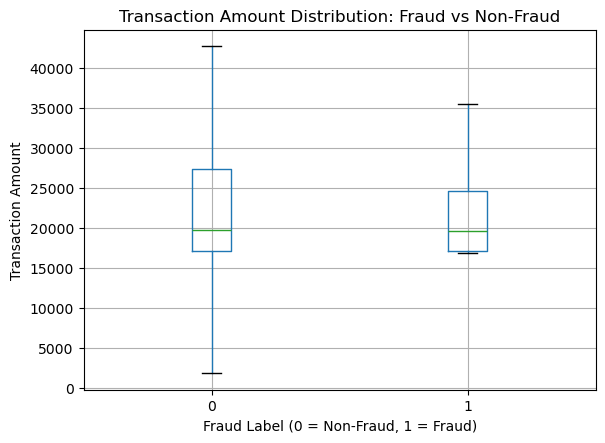

In [15]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

transfer_df.boxplot(
    column='amount',
    by='isFraud',
    showfliers=False
)

plt.title('Transaction Amount Distribution: Fraud vs Non-Fraud')
plt.suptitle('')
plt.xlabel('Fraud Label (0 = Non-Fraud, 1 = Fraud)')
plt.ylabel('Transaction Amount')
plt.show()


In [16]:

for label, group in transfer_df.groupby('isFraud'):
    print("\nFraud label:", label)
    print(group['amount'].quantile([0.50, 0.75, 0.90, 0.95, 0.99]))
    print("Mean:", group['amount'].mean())
    print("Standard deviation:", group['amount'].std())



Fraud label: 0
0.50     19733.600
0.75     27354.320
0.90     73580.280
0.95    143656.730
0.99    687535.252
Name: amount, dtype: float64
Mean: 49068.01350747824
Standard deviation: 116157.71269405022

Fraud label: 1
0.50    19631.62
0.75    24615.56
0.90    40116.90
0.95    73538.57
0.99    79809.30
Name: amount, dtype: float64
Mean: 25486.856223407292
Standard deviation: 17980.355817731677


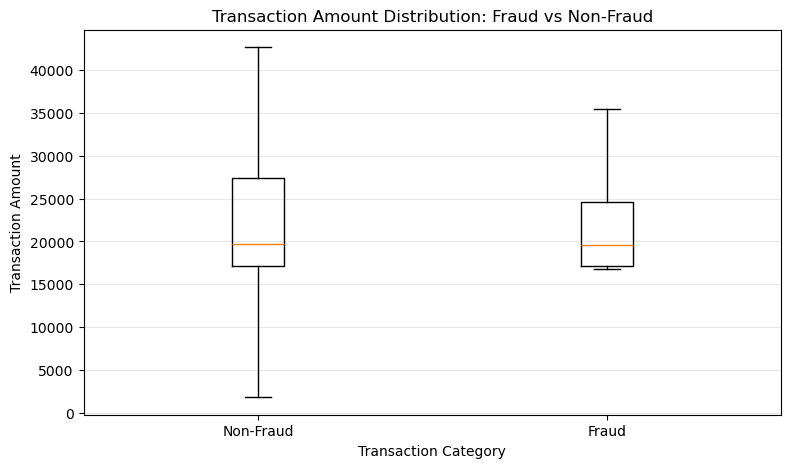

In [17]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.boxplot(
    [
        transfer_df.loc[transfer_df['isFraud'] == 0, 'amount'],
        transfer_df.loc[transfer_df['isFraud'] == 1, 'amount']
    ],
    tick_labels=['Non-Fraud', 'Fraud'],
    showfliers=False
)

plt.title('Transaction Amount Distribution: Fraud vs Non-Fraud')
plt.xlabel('Transaction Category')
plt.ylabel('Transaction Amount')
plt.grid(axis='y', alpha=0.3)
plt.show()


In [18]:

from scipy.stats import mannwhitneyu

non_fraud_amounts = transfer_df.loc[
    transfer_df['isFraud'] == 0, 'amount'
]

fraud_amounts = transfer_df.loc[
    transfer_df['isFraud'] == 1, 'amount'
]

u_stat, p_value = mannwhitneyu(
    fraud_amounts,
    non_fraud_amounts,
    alternative='two-sided'
)

n1 = len(fraud_amounts)
n2 = len(non_fraud_amounts)

rank_biserial = (2 * u_stat / (n1 * n2)) - 1

print("Mann-Whitney U:", u_stat)
print("P-value:", p_value)
print("Rank-biserial correlation:", rank_biserial)


Mann-Whitney U: 32471323480.0
P-value: 2.23211743710987e-291
Rank-biserial correlation: -0.06044634944015459


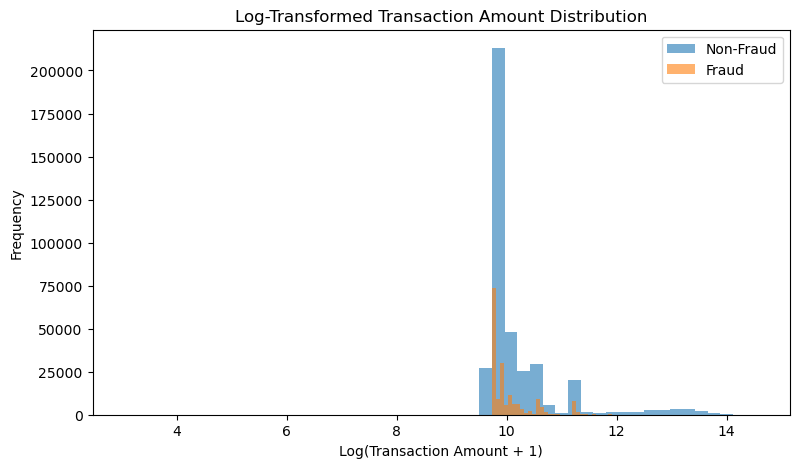

In [19]:

import numpy as np
import matplotlib.pyplot as plt

transfer_df['log_amount'] = np.log1p(transfer_df['amount'])

plt.figure(figsize=(9, 5))

plt.hist(
    transfer_df.loc[transfer_df['isFraud'] == 0, 'log_amount'],
    bins=50,
    alpha=0.6,
    label='Non-Fraud'
)

plt.hist(
    transfer_df.loc[transfer_df['isFraud'] == 1, 'log_amount'],
    bins=50,
    alpha=0.6,
    label='Fraud'
)

plt.title('Log-Transformed Transaction Amount Distribution')
plt.xlabel('Log(Transaction Amount + 1)')
plt.ylabel('Frequency')
plt.legend()
plt.show()


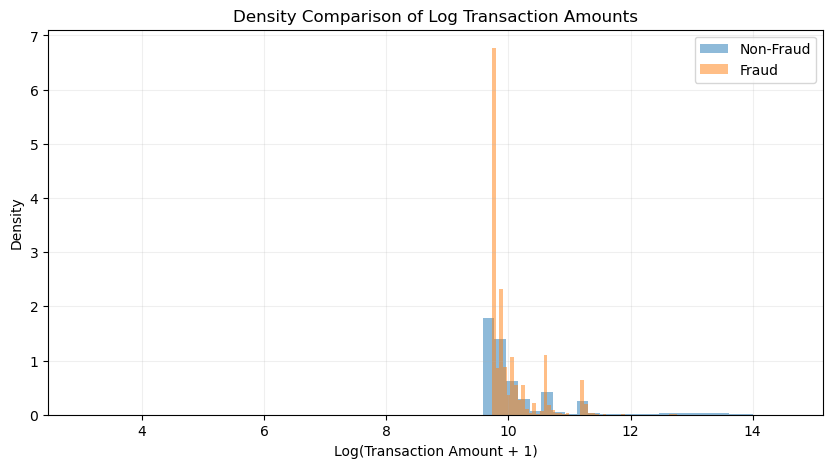

In [20]:

plt.figure(figsize=(10, 5))

plt.hist(
    transfer_df.loc[transfer_df['isFraud'] == 0, 'log_amount'],
    bins=60,
    density=True,
    alpha=0.5,
    label='Non-Fraud'
)

plt.hist(
    transfer_df.loc[transfer_df['isFraud'] == 1, 'log_amount'],
    bins=60,
    density=True,
    alpha=0.5,
    label='Fraud'
)

plt.title('Density Comparison of Log Transaction Amounts')
plt.xlabel('Log(Transaction Amount + 1)')
plt.ylabel('Density')
plt.legend()
plt.grid(alpha=0.2)
plt.show()


In [21]:

# Compare the most frequently occurring transaction amounts

for label in [0, 1]:
    print(f"\nFraud label: {label}")

    print(
        transfer_df.loc[
            transfer_df['isFraud'] == label, 'amount'
        ].value_counts().head(10)
    )



Fraud label: 0
amount
21966.03    4012
17023.68    3963
19769.43    3961
19220.28    3961
17972.21    3947
17389.78    3946
17847.40    3944
16840.63    3935
17298.25    3929
16886.39    3924
Name: count, dtype: int64

Fraud label: 1
amount
21966.03    1927
16908.07    1902
16932.15    1899
19220.28    1897
16848.95    1896
16989.35    1896
16825.05    1884
16945.23    1883
17190.81    1881
18828.03    1880
Name: count, dtype: int64


## 8. Fraud Patterns Across Transaction Steps

In [22]:

# Fraud distribution across transaction steps

step_analysis = (
    transfer_df.groupby('step')
    .agg(
        total_transactions=('isFraud', 'count'),
        fraud_transactions=('isFraud', 'sum')
    )
)

step_analysis['fraud_rate_pct'] = (
    step_analysis['fraud_transactions'] /
    step_analysis['total_transactions'] * 100
)

display(step_analysis.sort_values(
    'fraud_rate_pct', ascending=False
).head(15).round(2))


,total_transactions,fraud_transactions,fraud_rate_pct
step,,,
1,2556,1273,49.80
0,2402,1177,49.00
2,2689,1265,47.04
3,2652,1205,45.44
4,2614,1158,44.30
5,2501,1106,44.22
7,2505,1064,42.48
6,2437,1015,41.65
8,2900,1115,38.45


In [23]:

# Fraud rate by transaction step range

transfer_df['step_group'] = pd.cut(
    transfer_df['step'],
    bins=[-1, 20, 40, 60, 80, 100, 120, 143],
    labels=[
        '0-20', '21-40', '41-60', '61-80',
        '81-100', '101-120', '121-143'
    ]
)

step_group_analysis = (
    transfer_df.groupby('step_group', observed=False)
    .agg(
        total_transactions=('isFraud', 'count'),
        fraud_transactions=('isFraud', 'sum'),
        fraud_rate=('isFraud', 'mean')
    )
)

step_group_analysis['fraud_rate'] *= 100

display(step_group_analysis.round(2))


,total_transactions,fraud_transactions,fraud_rate
step_group,,,
0-20,72382,25319,34.98
21-40,81770,24655,30.15
41-60,84072,24741,29.43
61-80,78594,24462,31.12
81-100,78844,24329,30.86
101-120,78590,24074,30.63
121-143,95076,27938,29.38


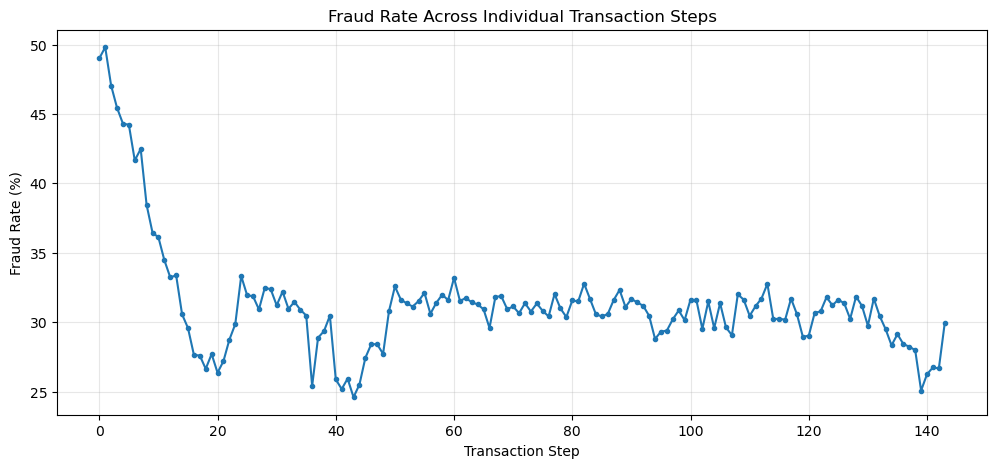

In [24]:

# Calculate fraud rate for every individual step

step_trend = (
    transfer_df.groupby('step')
    .agg(
        total_transactions=('isFraud', 'count'),
        fraud_transactions=('isFraud', 'sum')
    )
)

step_trend['fraud_rate_pct'] = (
    step_trend['fraud_transactions'] /
    step_trend['total_transactions'] * 100
)

plt.figure(figsize=(12, 5))

plt.plot(
    step_trend.index,
    step_trend['fraud_rate_pct'],
    marker='o',
    markersize=3
)

plt.title('Fraud Rate Across Individual Transaction Steps')
plt.xlabel('Transaction Step')
plt.ylabel('Fraud Rate (%)')
plt.grid(alpha=0.3)
plt.show()


## 9. Sender and Recipient Account Fraud Analysis

In [25]:

# Sender account fraud analysis

sender_analysis = (
    transfer_df.groupby('initiator')
    .agg(
        total_transfers=('isFraud', 'count'),
        fraud_transfers=('isFraud', 'sum')
    )
)

sender_analysis['fraud_rate_pct'] = (
    sender_analysis['fraud_transfers'] /
    sender_analysis['total_transfers'] * 100
)

# Accounts with at least 5 transfers
frequent_senders = sender_analysis[
    sender_analysis['total_transfers'] >= 5
]

print("Total unique sender accounts:", len(sender_analysis))
print("Sender accounts with 5+ transfers:", len(frequent_senders))

print("\nTop 15 sender accounts by fraud count:")
display(
    sender_analysis.sort_values(
        'fraud_transfers', ascending=False
    ).head(15).round(2)
)


Total unique sender accounts: 11063
Sender accounts with 5+ transfers: 8869

Top 15 sender accounts by fraud count:


,total_transfers,fraud_transfers,fraud_rate_pct
initiator,,,
4654047633050507,644,198,30.75
4971664085133015,640,184,28.75
4828576380583261,583,154,26.42
4945482194025615,506,149,29.45
4897326195323396,539,148,27.46
4703522567226712,547,146,26.69
4965633056540175,414,145,35.02
4786690100874361,468,143,30.56
4623791971135069,475,143,30.11


In [26]:

# Overall fraud concentration among sender accounts

sender_analysis['fraud_account_flag'] = (
    sender_analysis['fraud_transfers'] > 0
)

print("Total sender accounts:", len(sender_analysis))

print(
    "Accounts with at least one fraud-labelled transfer:",
    sender_analysis['fraud_account_flag'].sum()
)

print(
    "Percentage of accounts with fraud-labelled transfers:",
    round(sender_analysis['fraud_account_flag'].mean() * 100, 2),
    "%"
)


Total sender accounts: 11063
Accounts with at least one fraud-labelled transfer: 10286
Percentage of accounts with fraud-labelled transfers: 92.98 %


In [27]:

# Recipient account fraud analysis

recipient_analysis = (
    transfer_df.groupby('recipient')
    .agg(
        total_transfers=('isFraud', 'count'),
        fraud_transfers=('isFraud', 'sum')
    )
)

recipient_analysis['fraud_rate_pct'] = (
    recipient_analysis['fraud_transfers'] /
    recipient_analysis['total_transfers'] * 100
)

print("Total unique recipient accounts:", len(recipient_analysis))

print("\nTop 15 recipient accounts by fraud count:")

display(
    recipient_analysis.sort_values(
        'fraud_transfers', ascending=False
    ).head(15).round(2)
)


Total unique recipient accounts: 10349

Top 15 recipient accounts by fraud count:


,total_transfers,fraud_transfers,fraud_rate_pct
recipient,,,
4556597991782819,116,54,46.55
4536601021496708,111,53,47.75
4928304117905205,117,53,45.30
4773918229931910,115,53,46.09
4613109388009177,112,52,46.43
4167286055007054,114,52,45.61
4868563943315747,115,51,44.35
4134254650623295,115,51,44.35
4506433487970711,114,51,44.74


In [28]:

recipient_analysis['fraud_account_flag'] = (
    recipient_analysis['fraud_transfers'] > 0
)

print(
    "Recipients with at least one fraud-labelled transfer:",
    recipient_analysis['fraud_account_flag'].sum()
)

print(
    "Percentage of recipients with fraud-labelled transfers:",
    round(recipient_analysis['fraud_account_flag'].mean() * 100, 2),
    "%"
)


Recipients with at least one fraud-labelled transfer: 5000
Percentage of recipients with fraud-labelled transfers: 48.31 %


In [29]:

# Analyse recipient accounts with at least 5 transfers

frequent_recipients = recipient_analysis[
    recipient_analysis['total_transfers'] >= 5
].copy()

print("Recipient accounts with 5+ transfers:",
      len(frequent_recipients))

print("\nRecipient fraud-rate distribution:")

display(
    frequent_recipients['fraud_rate_pct']
    .describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95]
    )
    .round(2)
)


Recipient accounts with 5+ transfers: 6247

Recipient fraud-rate distribution:


count    6247.00
mean       25.49
std        13.34
min         0.00
25%        25.23
50%        30.36
75%        33.94
90%        36.97
95%        38.79
max        47.75
Name: fraud_rate_pct, dtype: float64

In [30]:

# Group recipients by their observed fraud rate

frequent_recipients['risk_band'] = pd.cut(
    frequent_recipients['fraud_rate_pct'],
    bins=[-0.01, 0, 10, 25, 40, 60, 100],
    labels=[
        'No fraud-labelled transfers',
        'Above 0% to 10%',
        'Above 10% to 25%',
        'Above 25% to 40%',
        'Above 40% to 60%',
        'Above 60%'
    ]
)

risk_distribution = (
    frequent_recipients.groupby(
        'risk_band', observed=False
    )
    .size()
    .reset_index(name='account_count')
)

risk_distribution['account_percentage'] = (
    risk_distribution['account_count'] /
    len(frequent_recipients) * 100
)

display(risk_distribution.round(2))


,risk_band,account_count,account_percentage
0,No fraud-labelled transfers,1247,19.96
1,Above 0% to 10%,0,0.00
2,Above 10% to 25%,307,4.91
3,Above 25% to 40%,4510,72.19
4,Above 40% to 60%,183,2.93
5,Above 60%,0,0.00


In [31]:

# Compare account balance conditions in fraudulent transfers

fraud_pattern_analysis = (
    transfer_df.groupby('isFraud')
    .agg(
        transaction_count=('amount', 'count'),
        sender_zero_balance=(
            'newBalInitiator',
            lambda x: (x == 0).mean() * 100
        ),
        recipient_zero_balance=(
            'newBalRecipient',
            lambda x: (x == 0).mean() * 100
        ),
        sender_negative_balance=(
            'newBalInitiator',
            lambda x: (x < 0).mean() * 100
        ),
        recipient_negative_balance=(
            'newBalRecipient',
            lambda x: (x < 0).mean() * 100
        )
    )
)

display(fraud_pattern_analysis.round(3))



,transaction_count,sender_zero_balance,recipient_zero_balance,sender_negative_balance,recipient_negative_balance
isFraud,,,,,
0,393810,0.0,1.192,3.592,0.004
1,175518,0.0,2.713,3.515,0.000


In [32]:

# Calculate proportion of sender balance consumed

transfer_df['sender_balance_utilization'] = (
    transfer_df['amount'] /
    (transfer_df['oldBalInitiator'].abs() + 1)
)

# Compare utilization between fraud and non-fraud
utilization_analysis = (
    transfer_df.groupby('isFraud')['sender_balance_utilization']
    .agg(
        mean='mean',
        median='median',
        q75=lambda x: x.quantile(0.75),
        q90=lambda x: x.quantile(0.90),
        q95=lambda x: x.quantile(0.95)
    )
)

display(utilization_analysis.round(4))


,mean,median,q75,q90,q95
isFraud,,,,,
0,1.6304,0.0087,0.0191,0.1090,0.2876
1,1.0183,0.0089,0.0217,0.3316,1.1276


In [33]:

# Investigate transactions where amount exceeds
# the sender's absolute starting balance

transfer_df['amount_exceeds_sender_balance'] = (
    transfer_df['amount'] >
    transfer_df['oldBalInitiator'].abs()
)

high_utilization_analysis = (
    transfer_df.groupby('isFraud')
    .agg(
        total_transactions=('amount', 'count'),
        amount_exceeds_balance=(
            'amount_exceeds_sender_balance', 'sum'
        ),
        negative_starting_balance=(
            'oldBalInitiator', lambda x: (x < 0).sum()
        ),
        zero_starting_balance=(
            'oldBalInitiator', lambda x: (x == 0).sum()
        )
    )
)

high_utilization_analysis['exceeds_balance_pct'] = (
    high_utilization_analysis['amount_exceeds_balance'] /
    high_utilization_analysis['total_transactions'] * 100
)

display(high_utilization_analysis.round(2))


,total_transactions,amount_exceeds_balance,negative_starting_balance,zero_starting_balance,exceeds_balance_pct
isFraud,,,,,
0,393810,8475,12916,0,2.15
1,175518,10081,5649,0,5.74


In [34]:

# Display the 10 highest utilization transactions

display(
    transfer_df.nlargest(
        10, 'amount_to_sender_balance_ratio'
    )[
        [
            'amount',
            'oldBalInitiator',
            'newBalInitiator',
            'amount_to_sender_balance_ratio',
            'isFraud'
        ]
    ]
)


,amount,oldBalInitiator,newBalInitiator,amount_to_sender_balance_ratio,isFraud
82615,979869.98,4.10,4.10,192131.368627,0
174528,478421.62,9.22,9.22,46812.291585,0
117179,1130838.66,24.77,24.77,43881.981374,0
119857,910708.12,24.41,24.41,35840.539945,0
79112,618161.76,20.60,20.60,28618.600000,0
55602,1137180.18,39.13,39.13,28337.407924,0
436829,77814.07,1.81,1.81,27691.839858,1
105170,695427.18,38.87,38.87,17442.367193,0
111523,751393.40,43.97,43.97,16708.770291,0
222545,167357.79,9.33,9.33,16201.141336,0


In [35]:

# Recalculate sender balance utilization safely

transfer_df['sender_balance_utilization'] = (
    transfer_df['amount'] /
    transfer_df['oldBalInitiator'].abs().replace(0, np.nan)
)

# Inspect the highest utilization records
extreme_transactions = transfer_df.nlargest(
    10, 'sender_balance_utilization'
)

display(
    extreme_transactions[
        [
            'amount',
            'oldBalInitiator',
            'newBalInitiator',
            'sender_balance_change',
            'sender_balance_utilization',
            'isFraud'
        ]
    ].to_string(index=False)
)


'    amount  oldBalInitiator  newBalInitiator  sender_balance_change  sender_balance_utilization  isFraud\n 979869.98             4.10             4.10                    0.0               238992.678049        0\n  17972.21             0.16             0.16                    0.0               112326.312500        1\n 478421.62             9.22             9.22                    0.0                51889.546638        0\n1130838.66            24.77            24.77                    0.0                45653.559144        0\n  77814.07             1.81             1.81                    0.0                42991.198895        1\n 910708.12            24.41            24.41                    0.0                37308.812782        0\n 618161.76            20.60            20.60                    0.0                30007.852427        0\n1137180.18            39.13            39.13                    0.0                29061.594173        0\n 167357.79             9.33             9.33 

In [36]:

# Compare actual sender balance reduction with transaction amount

transfer_df['sender_balance_change_check'] = (
    transfer_df['oldBalInitiator'] -
    transfer_df['newBalInitiator']
)

transfer_df['sender_balance_gap'] = (
    transfer_df['sender_balance_change_check'] -
    transfer_df['amount']
)

display(
    transfer_df.groupby('isFraud')['sender_balance_gap']
    .agg(['mean', 'median', 'std'])
    .round(2)
)


,mean,median,std
isFraud,,,
0,-1859.59,-0.0,20168.12
1,-2513.88,-0.0,13799.10


In [37]:

# Compare fraud rates across sender balance conditions

transfer_df['sender_balance_status'] = np.select(
    [
        transfer_df['oldBalInitiator'] < 0,
        transfer_df['oldBalInitiator'] == 0,
        transfer_df['oldBalInitiator'] <= 100,
        transfer_df['oldBalInitiator'] <= 10000
    ],
    [
        'Negative balance',
        'Zero balance',
        'Very low balance',
        'Low balance'
    ],
    default='Normal balance'
)

balance_status_analysis = (
    transfer_df.groupby('sender_balance_status', observed=False)
    .agg(
        total_transactions=('isFraud', 'count'),
        fraud_transactions=('isFraud', 'sum'),
        fraud_rate=('isFraud', 'mean')
    )
)

balance_status_analysis['fraud_rate'] *= 100

display(balance_status_analysis.round(2))



,total_transactions,fraud_transactions,fraud_rate
sender_balance_status,,,
Low balance,4232,2900,68.53
Negative balance,18565,5649,30.43
Normal balance,546437,166918,30.55
Very low balance,94,51,54.26


In [38]:

# Account-level analysis by sender balance category

balance_account_analysis = (
    transfer_df.groupby('sender_balance_status')
    .agg(
        unique_senders=('initiator', 'nunique'),
        total_transactions=('isFraud', 'count'),
        fraud_transactions=('isFraud', 'sum'),
        fraud_rate=('isFraud', 'mean')
    )
)

balance_account_analysis['fraud_rate'] *= 100

display(balance_account_analysis.round(2))


,unique_senders,total_transactions,fraud_transactions,fraud_rate
sender_balance_status,,,,
Low balance,1223,4232,2900,68.53
Negative balance,2391,18565,5649,30.43
Normal balance,10811,546437,166918,30.55
Very low balance,91,94,51,54.26


In [39]:

# Account-level fraud rate within low-balance senders

low_balance_accounts = (
    transfer_df[
        transfer_df['sender_balance_status'] == 'Low balance'
    ]
    .groupby('initiator')
    .agg(
        total_transfers=('isFraud', 'count'),
        fraud_transfers=('isFraud', 'sum')
    )
)

low_balance_accounts['fraud_rate_pct'] = (
    low_balance_accounts['fraud_transfers'] /
    low_balance_accounts['total_transfers'] * 100
)

print("Number of low-balance senders:",
      len(low_balance_accounts))

print("\nAccount-level fraud-rate distribution:")

display(
    low_balance_accounts['fraud_rate_pct']
    .describe()
    .round(2)
)


Number of low-balance senders: 1223

Account-level fraud-rate distribution:


count    1223.00
mean       56.66
std        46.91
min         0.00
25%         0.00
50%       100.00
75%       100.00
max       100.00
Name: fraud_rate_pct, dtype: float64

In [40]:

# Examine transaction volume for low-balance sender accounts

print("Transaction count distribution:")

display(
    low_balance_accounts['total_transfers']
    .describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95]
    )
    .round(2)
)

print("\nAccounts with only one transaction:",
      (low_balance_accounts['total_transfers'] == 1).sum())

print("Accounts with 2-5 transactions:",
      low_balance_accounts['total_transfers'].between(2, 5).sum())

print("Accounts with more than 5 transactions:",
      (low_balance_accounts['total_transfers'] > 5).sum())


Transaction count distribution:


count    1223.00
mean        3.46
std         5.00
min         1.00
25%         1.00
50%         1.00
75%         3.00
90%        10.00
95%        15.00
max        36.00
Name: total_transfers, dtype: float64


Accounts with only one transaction: 705
Accounts with 2-5 transactions: 307
Accounts with more than 5 transactions: 211


## 10. Model Preparation and Feature Selection

In [41]:

# Check the final feature candidates

candidate_features = [
    'step',
    'amount',
    'sender_balance_difference',
    'recipient_balance_difference',
    'sender_balance_mismatch',
    'recipient_balance_mismatch',
    'sender_mismatch_flag',
    'recipient_mismatch_flag',
    'isFraud'
]

model_data = transfer_df[candidate_features].copy()

print("Model dataset shape:", model_data.shape)

print("\nMissing values:")
display(model_data.isnull().sum())

print("\nData types:")
display(model_data.dtypes)


Model dataset shape: (569328, 9)

Missing values:


step                            0
amount                          0
sender_balance_difference       0
recipient_balance_difference    0
sender_balance_mismatch         0
recipient_balance_mismatch      0
sender_mismatch_flag            0
recipient_mismatch_flag         0
isFraud                         0
dtype: int64


Data types:


step                              int64
amount                          float64
sender_balance_difference       float64
recipient_balance_difference    float64
sender_balance_mismatch         float64
recipient_balance_mismatch      float64
sender_mismatch_flag              int64
recipient_mismatch_flag           int64
isFraud                           int64
dtype: object

In [42]:

# Compare feature distributions by fraud label

feature_summary = (
    model_data.groupby('isFraud')
    .mean()
    .T
)

feature_summary.columns = ['Non-Fraud', 'Fraud']

feature_summary['absolute_difference'] = (
    feature_summary['Fraud'] -
    feature_summary['Non-Fraud']
).abs()

display(
    feature_summary.sort_values(
        'absolute_difference',
        ascending=False
    ).round(4)
)


,Non-Fraud,Fraud,absolute_difference
amount,49068.0135,25486.8562,23581.1573
sender_balance_difference,-1859.5877,-2513.8758,654.2882
recipient_balance_difference,-1859.5876,-2513.8758,654.2881
sender_balance_mismatch,1859.5897,2513.8778,654.2880
recipient_balance_mismatch,1859.5889,2513.8769,654.2880
step,73.5345,71.4009,2.1336
sender_mismatch_flag,0.1421,0.1712,0.0291
recipient_mismatch_flag,0.1078,0.1366,0.0287


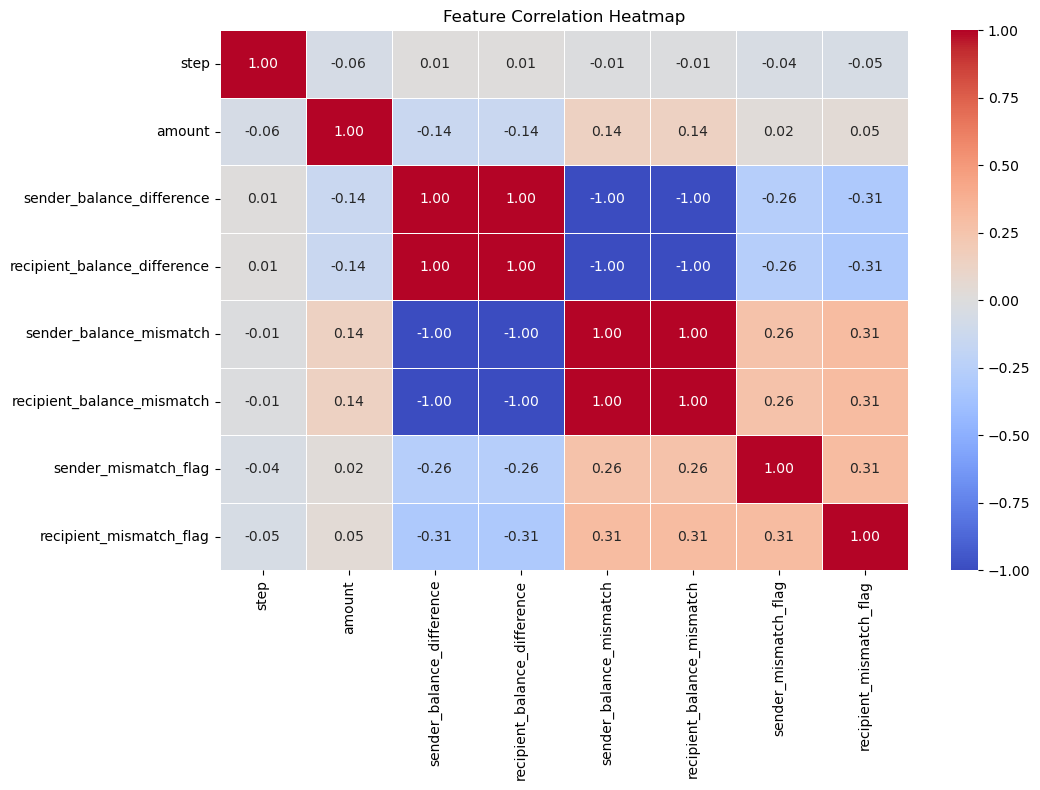

In [43]:

import seaborn as sns
import matplotlib.pyplot as plt

# Calculate correlations between candidate features
correlation_matrix = model_data.drop(
    columns='isFraud'
).corr()

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    center=0,
    linewidths=0.5
)

plt.title('Feature Correlation Heatmap')
plt.tight_layout()
plt.show()


In [44]:

# Identify feature pairs with absolute correlation above 0.90

corr_pairs = (
    correlation_matrix.where(
        np.triu(
            np.ones(correlation_matrix.shape),
            k=1
        ).astype(bool)
    )
    .stack()
    .reset_index()
)

corr_pairs.columns = [
    'Feature 1', 'Feature 2', 'Correlation'
]

high_corr_pairs = corr_pairs[
    corr_pairs['Correlation'].abs() > 0.90
].sort_values(
    'Correlation',
    key=lambda x: x.abs(),
    ascending=False
)

display(high_corr_pairs.round(4))


,Feature 1,Feature 2,Correlation
13,sender_balance_difference,recipient_balance_difference,1.0
19,recipient_balance_difference,recipient_balance_mismatch,-1.0
22,sender_balance_mismatch,recipient_balance_mismatch,1.0
15,sender_balance_difference,recipient_balance_mismatch,-1.0
14,sender_balance_difference,sender_balance_mismatch,-1.0
18,recipient_balance_difference,sender_balance_mismatch,-1.0


In [45]:

# Check whether sender and recipient balance differences
# are exactly equal for every transaction

print(
    "Differences equal:",
    np.allclose(
        transfer_df['sender_balance_difference'],
        transfer_df['recipient_balance_difference']
    )
)

# Check whether mismatch values are equal
print(
    "Mismatch values equal:",
    np.allclose(
        transfer_df['sender_balance_mismatch'],
        transfer_df['recipient_balance_mismatch']
    )
)

# Check whether mismatch is simply the absolute difference
print(
    "Mismatch is absolute difference:",
    np.allclose(
        transfer_df['sender_balance_mismatch'],
        transfer_df['sender_balance_difference'].abs()
    )
)


Differences equal: False
Mismatch values equal: False
Mismatch is absolute difference: True


In [46]:

# Calculate the difference between sender and recipient features

balance_gap = (
    transfer_df['sender_balance_difference']
    - transfer_df['recipient_balance_difference']
).abs()

print("Maximum difference:", balance_gap.max())
print("Mean difference:", balance_gap.mean())
print("Median difference:", balance_gap.median())

print(
    "Rows with different values:",
    (balance_gap > 0.01).sum()
)

print(
    "Percentage of rows with different values:",
    round((balance_gap > 0.01).mean() * 100, 2), "%"
)


Maximum difference: 0.010000001639127731
Mean difference: 0.0029383941241593
Median difference: 1.709850039333105e-10
Rows with different values: 82762
Percentage of rows with different values: 14.54 %


In [47]:

print(
    balance_gap.describe(
        percentiles=[0.90, 0.95, 0.99, 0.999]
    )
)

print("\nGap value distribution (rounded to 4 decimals):")

display(
    balance_gap.round(4)
    .value_counts()
    .head(10)
)


count    5.693280e+05
mean     2.938394e-03
std      4.555197e-03
min      0.000000e+00
50%      1.709850e-10
90%      1.000000e-02
95%      1.000000e-02
99%      1.000000e-02
99.9%    1.000000e-02
max      1.000000e-02
dtype: float64

Gap value distribution (rounded to 4 decimals):


0.00    402037
0.01    167291
Name: count, dtype: int64

In [48]:

selected_features = [
    'step',
    'amount',
    'sender_balance_difference',
    'sender_mismatch_flag',
    'recipient_mismatch_flag',
    'isFraud'
]

model_data_v2 = transfer_df[selected_features].copy()

print("New dataset shape:", model_data_v2.shape)
display(model_data_v2.head())


New dataset shape: (569328, 6)


,step,amount,sender_balance_difference,sender_mismatch_flag,recipient_mismatch_flag,isFraud
0,0,19824.96,-7.275958e-12,0,0,1
3,0,19847.01,0.000000e+00,0,1,1
5,0,16973.75,1.000000e-02,1,0,1
7,0,21103.99,-1.091394e-11,0,0,1
9,0,16908.07,-1.690807e+04,1,1,1


In [49]:

# Compare balance difference patterns between fraud and non-fraud

display(
    model_data_v2.groupby('isFraud')[
        ['sender_balance_difference',
         'sender_mismatch_flag',
         'recipient_mismatch_flag']
    ].agg(['mean', 'median', 'min', 'max']).round(4)
)

# Check how often sender balance difference is approximately zero
model_data_v2['sender_difference_zero'] = (
    model_data_v2['sender_balance_difference'].abs() < 0.01
)

display(
    pd.crosstab(
        model_data_v2['sender_difference_zero'],
        model_data_v2['isFraud'],
        normalize='index'
    ).round(4) * 100
)


sender_balance_difference                           \
                             mean median         min   max   
isFraud                                                      
0                      -1859.5877   -0.0 -1456202.83  0.01   
1                      -2513.8758   -0.0  -632938.42  0.01   

        sender_mismatch_flag                recipient_mismatch_flag         \
                        mean median min max                    mean median   
isFraud                                                                      
0                     0.1421    0.0   0   1                  0.1078    0.0   
1                     0.1712    0.0   0   1                  0.1366    0.0   

                 
        min max  
isFraud          
0         0   1  
1         0   1

isFraud,0,1
sender_difference_zero,,
False,65.07,34.93
True,69.90,30.10


In [50]:

# Fraud rate for each combination of mismatch flags

display(
    model_data_v2.groupby(
        ['sender_mismatch_flag', 'recipient_mismatch_flag']
    )['isFraud']
    .agg(['count', 'sum', 'mean'])
    .assign(
        fraud_rate=lambda x: x['mean'] * 100
    )
    .drop(columns='mean')
    .round(2)
)


count     sum  fraud_rate
sender_mismatch_flag recipient_mismatch_flag                            
0                    0                        446975  134963       30.19
                     1                         36356   10512       28.91
1                    0                         55912   16582       29.66
                     1                         30085   13461       44.74

In [51]:

from scipy.stats import chi2_contingency

model_data_v2['both_mismatch'] = (
    (model_data_v2['sender_mismatch_flag'] == 1) &
    (model_data_v2['recipient_mismatch_flag'] == 1)
).astype(int)

contingency_table = pd.crosstab(
    model_data_v2['both_mismatch'],
    model_data_v2['isFraud']
)

chi2, p_value, dof, expected = chi2_contingency(
    contingency_table
)

n = contingency_table.to_numpy().sum()
cramers_v = np.sqrt(chi2 / n)

print("Chi-square:", chi2)
print("P-value:", p_value)
print("Cramer's V:", cramers_v)

display(contingency_table)


Chi-square: 2883.105880569535
P-value: 0.0
Cramer's V: 0.0711621440199951


isFraud,0,1
both_mismatch,,
0,377186,162057
1,16624,13461


In [52]:

final_candidate_data = transfer_df[
    [
        'step',
        'amount',
        'sender_balance_difference',
        'isFraud'
    ]
].copy()

final_candidate_data['both_mismatch'] = (
    (transfer_df['sender_mismatch_flag'] == 1) &
    (transfer_df['recipient_mismatch_flag'] == 1)
).astype(int)

print("Dataset shape:", final_candidate_data.shape)
display(final_candidate_data.head())


Dataset shape: (569328, 5)


,step,amount,sender_balance_difference,isFraud,both_mismatch
0,0,19824.96,-7.275958e-12,1,0
3,0,19847.01,0.000000e+00,1,0
5,0,16973.75,1.000000e-02,1,0
7,0,21103.99,-1.091394e-11,1,0
9,0,16908.07,-1.690807e+04,1,1


In [53]:
# Fraud distribution across transaction types

display(
    df.groupby('transactionType')['isFraud']
    .agg(
        total_transactions='count',
        fraud_transactions='sum',
        fraud_rate='mean'
    )
    .assign(
        fraud_rate=lambda x: x['fraud_rate'] * 100
    )
    .round(2)
)

,total_transactions,fraud_transactions,fraud_rate
transactionType,,,
DEBIT,5392,0,0.00
DEPOSIT,384431,0,0.00
PAYMENT,667245,0,0.00
TRANSFER,569328,175518,30.83
WITHDRAWAL,93785,0,0.00


In [54]:
# Class distribution in our final candidate dataset

class_counts = final_candidate_data['isFraud'].value_counts()

print("Class counts:")
display(class_counts)

print("\nClass percentages:")
display(
    final_candidate_data['isFraud']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Class counts:


isFraud
0    393810
1    175518
Name: count, dtype: int64


Class percentages:


isFraud
0    69.17
1    30.83
Name: proportion, dtype: float64

## 11. Train-Test Split and Model Preparation

In [55]:

from sklearn.model_selection import train_test_split

# Separate predictors and target
X = final_candidate_data.drop(columns='isFraud')
y = final_candidate_data['isFraud']

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
display(y_train.value_counts(normalize=True).mul(100).round(2))

print("\nTesting target distribution:")
display(y_test.value_counts(normalize=True).mul(100).round(2))


Training features: (455462, 4)
Testing features: (113866, 4)

Training target distribution:


isFraud
0    69.17
1    30.83
Name: proportion, dtype: float64


Testing target distribution:


isFraud
0    69.17
1    30.83
Name: proportion, dtype: float64

In [56]:

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Create pipeline
logistic_model = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Train model
logistic_model.fit(X_train, y_train)

print("Logistic Regression training completed!")


Logistic Regression training completed!


## 12. Logistic Regression Model Evaluation

In [57]:

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    roc_auc_score,
    average_precision_score
)

# Generate predictions
y_pred = logistic_model.predict(X_test)
y_prob = logistic_model.predict_proba(X_test)[:, 1]

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))
print("PR-AUC:", round(average_precision_score(y_test, y_prob), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))


Accuracy: 0.6947
ROC-AUC: 0.5545
PR-AUC: 0.3641

Classification Report:
              precision    recall  f1-score   support

           0       0.70      0.99      0.82     78762
           1       0.63      0.02      0.05     35104

    accuracy                           0.69    113866
   macro avg       0.66      0.51      0.43    113866
weighted avg       0.68      0.69      0.58    113866


Confusion Matrix:
[[78273   489]
 [34274   830]]


In [58]:

# Examine Logistic Regression coefficients

coefficient_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Coefficient': logistic_model.named_steps[
        'classifier'
    ].coef_[0]
})

coefficient_df['Absolute_Coefficient'] = (
    coefficient_df['Coefficient'].abs()
)

display(
    coefficient_df.sort_values(
        'Absolute_Coefficient',
        ascending=False
    ).round(4)
)


,Feature,Coefficient,Absolute_Coefficient
1,amount,-0.8502,0.8502
3,both_mismatch,0.1276,0.1276
2,sender_balance_difference,-0.0910,0.0910
0,step,-0.0630,0.0630


## 13. Random Forest Model Training

In [59]:

from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=12,
    min_samples_split=10,
    min_samples_leaf=5,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Random Forest training completed!")


Random Forest training completed!


In [60]:

# Predictions
rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)[:, 1]

print("Accuracy:", round(accuracy_score(y_test, rf_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, rf_prob), 4))
print("PR-AUC:", round(average_precision_score(y_test, rf_prob), 4))

print("\nClassification Report:")
print(classification_report(y_test, rf_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_pred))


Accuracy: 0.5837
ROC-AUC: 0.5604
PR-AUC: 0.381

Classification Report:
              precision    recall  f1-score   support

           0       0.71      0.67      0.69     78762
           1       0.35      0.40      0.37     35104

    accuracy                           0.58    113866
   macro avg       0.53      0.53      0.53    113866
weighted avg       0.60      0.58      0.59    113866


Confusion Matrix:
[[52525 26237]
 [21162 13942]]


,Feature,Importance
1,amount,0.6122
2,sender_balance_difference,0.2016
0,step,0.1441
3,both_mismatch,0.0421


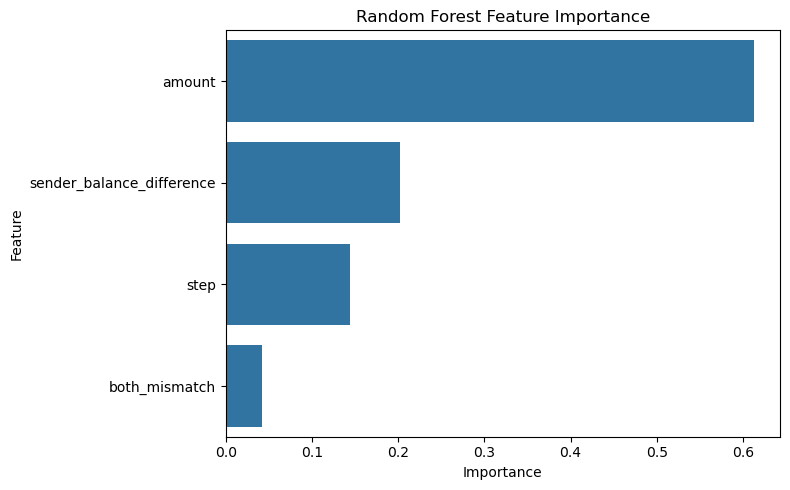

In [61]:

importance_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf_model.feature_importances_
})

importance_df = importance_df.sort_values(
    'Importance',
    ascending=False
)

display(importance_df.round(4))

# Visualise feature importance
plt.figure(figsize=(8, 5))

sns.barplot(
    data=importance_df,
    x='Importance',
    y='Feature'
)

plt.title('Random Forest Feature Importance')
plt.tight_layout()
plt.show()


## 14. Time-Based Train-Test Split

In [62]:

# Sort transfers by simulation step
time_data = final_candidate_data.sort_values(
    'step'
).copy()

# Find the 80th percentile step
split_step = time_data['step'].quantile(0.80)

print("Time split step:", split_step)

# Split chronologically
train_time = time_data[
    time_data['step'] <= split_step
]

test_time = time_data[
    time_data['step'] > split_step
]

print("Training shape:", train_time.shape)
print("Testing shape:", test_time.shape)

print("\nTraining fraud distribution:")
display(train_time['isFraud'].value_counts(normalize=True).mul(100).round(2))

print("\nTesting fraud distribution:")
display(test_time['isFraud'].value_counts(normalize=True).mul(100).round(2))


Time split step: 116.0
Training shape: (458383, 5)
Testing shape: (110945, 5)

Training fraud distribution:


isFraud
0    68.84
1    31.16
Name: proportion, dtype: float64


Testing fraud distribution:


isFraud
0    70.52
1    29.48
Name: proportion, dtype: float64

In [63]:

# Separate features and target

X_train_time = train_time.drop(columns='isFraud')
y_train_time = train_time['isFraud']

X_test_time = test_time.drop(columns='isFraud')
y_test_time = test_time['isFraud']

# Train Random Forest
rf_time_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=12,
    min_samples_split=10,
    min_samples_leaf=5,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

rf_time_model.fit(X_train_time, y_train_time)

print("Time-based Random Forest training completed!")


Time-based Random Forest training completed!


In [64]:

# Predictions
y_time_pred = rf_time_model.predict(X_test_time)
y_time_prob = rf_time_model.predict_proba(X_test_time)[:, 1]

print("Accuracy:", round(accuracy_score(y_test_time, y_time_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test_time, y_time_prob), 4))
print("PR-AUC:", round(average_precision_score(y_test_time, y_time_prob), 4))

print("\nClassification Report:")
print(classification_report(y_test_time, y_time_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_time, y_time_pred))


Accuracy: 0.6638
ROC-AUC: 0.5389
PR-AUC: 0.3217

Classification Report:
              precision    recall  f1-score   support

           0       0.71      0.88      0.79     78241
           1       0.33      0.14      0.20     32704

    accuracy                           0.66    110945
   macro avg       0.52      0.51      0.49    110945
weighted avg       0.60      0.66      0.61    110945


Confusion Matrix:
[[69125  9116]
 [28182  4522]]


## 15. Account-Level Activity Analysis

In [65]:

# Account-level activity summary

sender_activity = (
    transfer_df.groupby('initiator')
    .agg(
        total_sent=('amount', 'count'),
        average_sent=('amount', 'mean'),
        total_amount_sent=('amount', 'sum')
    )
)

recipient_activity = (
    transfer_df.groupby('recipient')
    .agg(
        total_received=('amount', 'count'),
        average_received=('amount', 'mean'),
        total_amount_received=('amount', 'sum')
    )
)

print("Unique sender accounts:", sender_activity.shape[0])
print("Unique recipient accounts:", recipient_activity.shape[0])

print("\nSender activity:")
display(sender_activity.describe().round(2))

print("\nRecipient activity:")
display(recipient_activity.describe().round(2))


Unique sender accounts: 11063
Unique recipient accounts: 10349

Sender activity:


,total_sent,average_sent,total_amount_sent
count,11063.00,11063.00,1.106300e+04
mean,51.46,48674.31,2.151033e+06
std,65.12,70229.71,3.445792e+06
min,1.00,4788.66,4.788660e+03
25%,7.00,19677.54,2.119038e+05
50%,28.00,28842.09,1.002141e+06
75%,71.00,49381.23,2.807624e+06
max,644.00,1206106.97,1.610970e+08



Recipient activity:


,total_received,average_received,total_amount_received
count,10349.00,10349.00,10349.00
mean,55.01,243489.44,2299437.28
std,53.65,253465.37,1522641.37
min,1.00,1120.06,1120.06
25%,2.00,26240.79,975059.92
50%,11.00,97969.05,2509105.51
75%,110.00,436168.95,3011672.34
max,137.00,2142928.28,13515396.40


In [66]:

# Create historical account behaviour features

def create_historical_features(data, account_col, prefix):

    # Aggregate transactions by account and simulation step
    history = (
        data.groupby([account_col, 'step'])['amount']
        .agg(
            transaction_count='size',
            amount_sum='sum'
        )
        .reset_index()
        .sort_values([account_col, 'step'])
    )

    # Calculate activity from earlier steps only
    history['previous_count'] = (
        history.groupby(account_col)['transaction_count']
        .cumsum() - history['transaction_count']
    )

    history['previous_amount'] = (
        history.groupby(account_col)['amount_sum']
        .cumsum() - history['amount_sum']
    )

    # Calculate historical average amount
    history['previous_average'] = (
        history['previous_amount'] /
        history['previous_count'].replace(0, np.nan)
    )

    # Rename columns
    history = history.rename(columns={
        'previous_count': f'{prefix}_previous_count',
        'previous_average': f'{prefix}_previous_avg_amount'
    })

    return history[
        [
            account_col,
            'step',
            f'{prefix}_previous_count',
            f'{prefix}_previous_avg_amount'
        ]
    ]


# Sender history
sender_history = create_historical_features(
    transfer_df, 'initiator', 'sender'
)

# Recipient history
recipient_history = create_historical_features(
    transfer_df, 'recipient', 'recipient'
)

# Merge historical features into transactions
enhanced_data = transfer_df.merge(
    sender_history,
    on=['initiator', 'step'],
    how='left'
)

enhanced_data = enhanced_data.merge(
    recipient_history,
    on=['recipient', 'step'],
    how='left'
)

# Fill missing history for first-time accounts
history_columns = [
    'sender_previous_count',
    'sender_previous_avg_amount',
    'recipient_previous_count',
    'recipient_previous_avg_amount'
]

enhanced_data[history_columns] = (
    enhanced_data[history_columns].fillna(0)
)

print("Enhanced dataset shape:", enhanced_data.shape)

display(
    enhanced_data[
        ['step', 'initiator', 'recipient'] + history_columns
    ].head(10)
)


Enhanced dataset shape: (569328, 31)


,step,initiator,recipient,sender_previous_count,sender_previous_avg_amount,recipient_previous_count,recipient_previous_avg_amount
0,0,4537027967639631,4875702729424478,0,0.0,0,0.0
1,0,4178224023847746,4096920916696293,0,0.0,0,0.0
2,0,4779013371563747,4593247015015219,0,0.0,0,0.0
3,0,4479448076398077,4649550475321678,0,0.0,0,0.0
4,0,4587942659105635,4863167876028593,0,0.0,0,0.0
5,0,4978866660478516,4822936618475944,0,0.0,0,0.0
6,0,4488893430580853,4622593723010843,0,0.0,0,0.0
7,0,4781213214714848,4663047917704976,0,0.0,0,0.0
8,0,4120037473988300,4187906273321880,0,0.0,0,0.0
9,0,4223078546024950,4840197438076267,0,0.0,0,0.0


In [67]:

# Check how many transactions have historical account activity

print("Original transfer rows:", len(transfer_df))
print("Enhanced dataset rows:", len(enhanced_data))

print("\nNon-zero historical feature counts:")

display(
    (enhanced_data[history_columns] > 0).sum()
)

print("\nHistorical feature summary:")

display(
    enhanced_data[history_columns].describe().round(2)
)

print("\nExample transactions from later steps:")

display(
    enhanced_data.loc[
        enhanced_data['step'] > 0,
        ['step', 'initiator', 'recipient'] + history_columns
    ].head(10)
)


Original transfer rows: 569328
Enhanced dataset rows: 569328

Non-zero historical feature counts:


sender_previous_count            556324
sender_previous_avg_amount       556324
recipient_previous_count         558723
recipient_previous_avg_amount    558723
dtype: int64


Historical feature summary:


,sender_previous_count,sender_previous_avg_amount,recipient_previous_count,recipient_previous_avg_amount
count,569328.00,569328.00,569328.00,569328.00
mean,65.93,49840.23,53.16,37847.99
std,69.57,47740.65,32.89,65031.70
min,0.00,0.00,0.00,0.00
25%,17.00,21842.66,24.00,22967.58
50%,43.00,37592.14,53.00,25729.59
75%,92.00,60432.48,81.00,31013.77
max,640.00,1585371.90,136.00,1585371.90



Example transactions from later steps:


,step,initiator,recipient,sender_previous_count,sender_previous_avg_amount,recipient_previous_count,recipient_previous_avg_amount
2402,1,4681157089477729,4922578055346110,0,0.000,0,0.00
2403,1,4889776731057975,4192389578958149,0,0.000,1,24615.56
2404,1,4793159699883127,4244380519320448,0,0.000,1,73294.25
2405,1,4647145349779011,4820762271547445,0,0.000,1,16817.74
2406,1,4332622544606900,4839403956144724,0,0.000,1,17572.83
2407,1,4220460601911318,4524553548501193,2,17279.675,1,19653.38
2408,1,4367764658042973,4007820533359739,0,0.000,1,17223.37
2409,1,4316430390819134,4115767307958965,1,17190.810,1,17084.69
2410,1,4851394003867099,4837768988487479,0,0.000,1,16973.75
2411,1,4568696648134360,4893751403705353,0,0.000,0,0.00


In [68]:

print("Original rows:", len(transfer_df))
print("Enhanced rows:", len(enhanced_data))

print("\nNon-zero historical values:")
display((enhanced_data[history_columns] > 0).sum())

print("\nMissing values:")
display(enhanced_data[history_columns].isna().sum())


Original rows: 569328
Enhanced rows: 569328

Non-zero historical values:


sender_previous_count            556324
sender_previous_avg_amount       556324
recipient_previous_count         558723
recipient_previous_avg_amount    558723
dtype: int64


Missing values:


sender_previous_count            0
sender_previous_avg_amount       0
recipient_previous_count         0
recipient_previous_avg_amount    0
dtype: int64

In [69]:

# Create improved modelling dataset

improved_features = [
    'step',
    'amount',
    'sender_balance_difference',
    'sender_mismatch_flag',
    'recipient_mismatch_flag',
    'sender_previous_count',
    'sender_previous_avg_amount',
    'recipient_previous_count',
    'recipient_previous_avg_amount',
    'isFraud'
]

improved_data = enhanced_data[improved_features].copy()

# Create combined mismatch feature
improved_data['both_mismatch'] = (
    (improved_data['sender_mismatch_flag'] == 1) &
    (improved_data['recipient_mismatch_flag'] == 1)
).astype(int)

# Remove individual mismatch flags
improved_data.drop(
    columns=[
        'sender_mismatch_flag',
        'recipient_mismatch_flag'
    ],
    inplace=True
)

print("Improved dataset shape:", improved_data.shape)
print("\nMissing values:")
display(improved_data.isnull().sum())

display(improved_data.head())


Improved dataset shape: (569328, 9)

Missing values:


step                             0
amount                           0
sender_balance_difference        0
sender_previous_count            0
sender_previous_avg_amount       0
recipient_previous_count         0
recipient_previous_avg_amount    0
isFraud                          0
both_mismatch                    0
dtype: int64

,step,amount,sender_balance_difference,sender_previous_count,sender_previous_avg_amount,recipient_previous_count,recipient_previous_avg_amount,isFraud,both_mismatch
0,0,19824.96,-7.275958e-12,0,0.0,0,0.0,1,0
1,0,19847.01,0.000000e+00,0,0.0,0,0.0,1,0
2,0,16973.75,1.000000e-02,0,0.0,0,0.0,1,0
3,0,21103.99,-1.091394e-11,0,0.0,0,0.0,1,0
4,0,16908.07,-1.690807e+04,0,0.0,0,0.0,1,1


## 16. Improved Model Preparation with Historical Features

In [70]:

# Sort data by simulation step
improved_data = improved_data.sort_values('step').copy()

# Split at step 116
train_improved = improved_data[
    improved_data['step'] <= 116
].copy()

test_improved = improved_data[
    improved_data['step'] > 116
].copy()

# Separate features and target
X_train_improved = train_improved.drop(columns='isFraud')
y_train_improved = train_improved['isFraud']

X_test_improved = test_improved.drop(columns='isFraud')
y_test_improved = test_improved['isFraud']

print("Training:", X_train_improved.shape)
print("Testing:", X_test_improved.shape)


Training: (458383, 8)
Testing: (110945, 8)


In [71]:

rf_improved = RandomForestClassifier(
    n_estimators=100,
    max_depth=12,
    min_samples_split=10,
    min_samples_leaf=5,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

rf_improved.fit(
    X_train_improved,
    y_train_improved
)

print("Improved Random Forest training completed!")


Improved Random Forest training completed!


In [72]:

rf_improved = RandomForestClassifier(
    n_estimators=100,
    max_depth=12,
    min_samples_split=10,
    min_samples_leaf=5,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

rf_improved.fit(X_train_improved, y_train_improved)

print("Improved Random Forest training completed!")


Improved Random Forest training completed!


In [73]:

# Generate predictions
y_improved_pred = rf_improved.predict(X_test_improved)

y_improved_prob = rf_improved.predict_proba(
    X_test_improved
)[:, 1]

# Evaluate model
print("Accuracy:",
      round(accuracy_score(y_test_improved, y_improved_pred), 4))

print("ROC-AUC:",
      round(roc_auc_score(y_test_improved, y_improved_prob), 4))

print("PR-AUC:",
      round(average_precision_score(y_test_improved, y_improved_prob), 4))

print("\nClassification Report:")
print(classification_report(y_test_improved, y_improved_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_improved, y_improved_pred))


Accuracy: 0.6706
ROC-AUC: 0.5454
PR-AUC: 0.3317

Classification Report:
              precision    recall  f1-score   support

           0       0.71      0.90      0.79     78241
           1       0.34      0.13      0.19     32704

    accuracy                           0.67    110945
   macro avg       0.53      0.51      0.49    110945
weighted avg       0.60      0.67      0.62    110945


Confusion Matrix:
[[70141  8100]
 [28446  4258]]


## 17. Chronological Validation Split

In [74]:

# Find the chronological validation cutoff
validation_cutoff = train_improved['step'].quantile(0.80)

print("Validation cutoff:", validation_cutoff)

# Split training data chronologically
train_core = train_improved[
    train_improved['step'] <= validation_cutoff
].copy()

validation_data = train_improved[
    train_improved['step'] > validation_cutoff
].copy()

# Separate features and target
X_core = train_core.drop(columns='isFraud')
y_core = train_core['isFraud']

X_val = validation_data.drop(columns='isFraud')
y_val = validation_data['isFraud']

print("\nCore training shape:", X_core.shape)
print("Validation shape:", X_val.shape)

print("\nCore training fraud rate:",
      round(y_core.mean() * 100, 2), "%")

print("Validation fraud rate:",
      round(y_val.mean() * 100, 2), "%")


Validation cutoff: 93.0

Core training shape: (367453, 8)
Validation shape: (90930, 8)

Core training fraud rate: 31.31 %
Validation fraud rate: 30.55 %


In [75]:

rf_tuned = RandomForestClassifier(
    n_estimators=100,
    max_depth=12,
    min_samples_split=10,
    min_samples_leaf=5,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

rf_tuned.fit(X_core, y_core)

print("Validation model training completed!")


Validation model training completed!


In [76]:

from sklearn.metrics import precision_recall_curve

val_prob = rf_tuned.predict_proba(X_val)[:, 1]

precision, recall, thresholds = precision_recall_curve(
    y_val,
    val_prob
)

print("Validation probabilities generated!")
print("Number of thresholds:", len(thresholds))


Validation probabilities generated!
Number of thresholds: 90354


In [77]:

from sklearn.metrics import precision_score, recall_score, f1_score

threshold_results = []

for threshold in [0.30, 0.40, 0.50]:
    val_pred = (val_prob >= threshold).astype(int)

    threshold_results.append({
        'Threshold': threshold,
        'Precision': precision_score(y_val, val_pred),
        'Recall': recall_score(y_val, val_pred),
        'F1_Score': f1_score(y_val, val_pred),
        'Fraud_Detected': int(
            ((y_val == 1) & (val_pred == 1)).sum()
        ),
        'False_Alarms': int(
            ((y_val == 0) & (val_pred == 1)).sum()
        )
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))


,Threshold,Precision,Recall,F1_Score,Fraud_Detected,False_Alarms
0,0.3,0.3075,0.9999,0.4704,27774,62541
1,0.4,0.3076,0.9992,0.4704,27756,62481
2,0.5,0.3303,0.2495,0.2843,6930,14050


In [78]:

# Calculate F1 score at every available threshold

f1_scores = (
    2 * precision[:-1] * recall[:-1] /
    (precision[:-1] + recall[:-1] + 1e-10)
)

best_index = np.argmax(f1_scores)

best_threshold = thresholds[best_index]
best_precision = precision[best_index]
best_recall = recall[best_index]
best_f1 = f1_scores[best_index]

print("Best threshold:", round(best_threshold, 4))
print("Precision:", round(best_precision, 4))
print("Recall:", round(best_recall, 4))
print("F1-score:", round(best_f1, 4))


Best threshold: 0.3835
Precision: 0.3076
Recall: 0.9996
F1-score: 0.4704


In [79]:

best_val_pred = (val_prob >= best_threshold).astype(int)

print(
    "Transactions flagged:",
    best_val_pred.sum()
)

print(
    "Percentage flagged:",
    round(best_val_pred.mean() * 100, 2), "%"
)

print(
    "False alarms:",
    ((best_val_pred == 1) & (y_val == 0)).sum()
)


Transactions flagged: 90267
Percentage flagged: 99.27 %
False alarms: 62501


In [80]:

thresholds_to_check = [
    0.45, 0.50, 0.55, 0.60,
    0.65, 0.70, 0.75, 0.80
]

results = []

for threshold in thresholds_to_check:

    predictions = (val_prob >= threshold).astype(int)

    results.append({
        'Threshold': threshold,
        'Precision': precision_score(y_val, predictions),
        'Recall': recall_score(y_val, predictions),
        'F1_Score': f1_score(y_val, predictions),
        'Fraud_Detected': (
            (predictions == 1) & (y_val == 1)
        ).sum(),
        'False_Alarms': (
            (predictions == 1) & (y_val == 0)
        ).sum(),
        'Flagged_Percentage': predictions.mean() * 100
    })

display(pd.DataFrame(results).round(4))



,Threshold,Precision,Recall,F1_Score,Fraud_Detected,False_Alarms,Flagged_Percentage
0,0.45,0.3074,0.9824,0.4682,27288,61496,97.6399
1,0.50,0.3303,0.2495,0.2843,6930,14050,23.0727
2,0.55,0.4147,0.0566,0.0996,1572,2219,4.1691
3,0.60,0.4350,0.0329,0.0611,913,1186,2.3084
4,0.65,0.4964,0.0147,0.0286,409,415,0.9062
5,0.70,0.6367,0.0071,0.0141,198,113,0.3420
6,0.75,0.7299,0.0046,0.0091,127,47,0.1914
7,0.80,0.8046,0.0025,0.0050,70,17,0.0957


## 18. Final Model Evaluation on Unseen Test Data

In [81]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

# Predict probabilities on the final test set
test_prob = rf_tuned.predict_proba(X_test_improved)[:, 1]

# Retain 0.50 as a validation-tested operating threshold.
# The F1-optimal threshold (0.3835) flagged 99.27% of validation
# transactions and generated 62,501 false alarms, so it was not
# selected as a practical operating point.
final_threshold = 0.50
test_predictions = (test_prob >= final_threshold).astype(int)

# Final evaluation
print("Final Threshold:", final_threshold)
print("\nConfusion Matrix:")
print(confusion_matrix(y_test_improved, test_predictions))

print("\nClassification Report:")
print(classification_report(y_test_improved, test_predictions))

print("ROC-AUC:", roc_auc_score(y_test_improved, test_prob))
print("PR-AUC:", average_precision_score(y_test_improved, test_prob))

Final Threshold: 0.5

Confusion Matrix:
[[63940 14301]
 [25570  7134]]

Classification Report:
              precision    recall  f1-score   support

           0       0.71      0.82      0.76     78241
           1       0.33      0.22      0.26     32704

    accuracy                           0.64    110945
   macro avg       0.52      0.52      0.51    110945
weighted avg       0.60      0.64      0.62    110945

ROC-AUC: 0.5471021679847337
PR-AUC: 0.32948489697230027


In [82]:
improved_data.to_csv(
    'fraud_analysis_data.csv',
    index=False
)

print("CSV file exported successfully!")

CSV file exported successfully!


## Final Conclusion

A Random Forest classifier was developed to identify fraud-labelled transactions
in a synthetic mobile money transaction dataset.

A chronological train-validation-test split was used to evaluate the model.
Historical sender and recipient transaction features were engineered using
previous simulation steps.

The final model achieved:
- Accuracy: 64%
- Precision: 33%
- Recall: 22%
- F1-score: 0.26
- ROC-AUC: 0.5471
- PR-AUC: 0.3295

The results indicate weak predictive performance. The model detected only
a small proportion of fraud-labelled transactions and generated a considerable
number of false alarms.


### Threshold selection

A threshold of 0.50 was retained for the final test evaluation after comparing
multiple thresholds on the validation set. Although the F1-optimal threshold
was 0.3835, it flagged 99.27% of validation transactions and produced 62,501
false alarms. The 0.50 threshold was therefore used as a more conservative
validation-tested operating point. It still has low recall, so the model is not
reliable enough for operational fraud detection.

### Limitations
1. The dataset is synthetic and its fraud labels should not be treated as
   representative of real-world fraud.
2. All fraud-labelled records in this dataset are TRANSFER transactions.
3. The model's performance is only marginally better than random ranking.
4. Post-transaction balance information limits its suitability for
   real-time fraud prevention.

### Conclusion
This project demonstrates an end-to-end machine learning workflow involving
data exploration, feature engineering, chronological data splitting,
classification, and evaluation. The results also highlight the challenges
of detecting fraud when the available features have limited predictive power.